# California 500 hPa ridging / 700 hPa warm-anomaly events (Jan-Apr, 1990-2025)

Looks for persistent (>= 5 consecutive days) periods where the California-box average
**500 hPa geopotential height** anomaly (ridging/blocking) or **700 hPa temperature**
anomaly (warm spells) exceeds +1, +2, or +3 standard deviations, using ERA5.

**Inputs:** `z500_t700_ca_<year>.nc`, produced by `get_z500_t700_ca.py` /
`job_array_get_z500_t700_ca.pbs`, one file per year, each holding daily-mean
500 hPa height (m) and 700 hPa temperature (K) on a California bounding box
(32.0-42.5N, 125.0-114.0W) for January-April only.

**Methodology**
- Box average: cosine-latitude-weighted mean over the CA box, one value per day per variable.
- Climatology: for each calendar day, the mean and standard deviation are computed by pooling that day +/- a 5-day window across all 36 years (1990-2025). This keeps the sample size per calendar day reasonable (~36 years x 11 days ~ 400 samples) while still tracking the Jan->Apr seasonal warming trend.
- Detrending: Fit a linear year-trend and remove it from the baseline before standardizing. Z500 has a real trend (+7.4 m/decade, p=0.045); T700's is smaller and not significant (+0.2 K/decade, p=0.17) but is removed too for consistency.
- Standardized anomaly = (value - detrended climatological mean) / climatological std, for that calendar day.
- "Ridging/blocking" and "high temperatures" are read as **positive** anomalies
  (height anomaly > 0 -> ridge; temperature anomaly > 0 -> warm). Set `SIGN = -1` in the event-detection cell to instead study troughs / cold spells.
- A run of days that exceeds the threshold is **one event**, regardless of how long it lasts, and gap-tolerant: up to `MAX_GAP` sub-threshold days within an otherwise persistent run don't split it into two events, since a real blocking regime can briefly dip below threshold (e.g. when reinforced by an impinging eddy) and reintensify without that being a new, separate episode. Events shorter than `MIN_DURATION` days are dropped.   

Ming Ge Oct 2026

In [4]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))  # 1990-2025 inclusive, excludes 2026
CLIM_WINDOW = 5                  # +/- days pooled around each calendar day for climatology
MIN_DURATION = 5                 # minimum consecutive days to count as an event
MAX_GAP = 1                      # max sub-threshold calendar days tolerated within an
                                 # event before it's considered two separate events --
                                 # lets a quasi-persistent, eddy-reinforced block that
                                 # briefly dips below threshold stay one event instead
                                 # of fragmenting into several
THRESHOLDS = [1, 2, 3]           # standard deviations
SIGN = 1                         # +1 = ridging/warm (as requested); -1 = troughs/cold

## 1. Load the CA-box daily data and build the box-averaged time series

In [5]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_z500_t700_ca.pbs first (see get_z500_t700_ca.py).'
    )

ds = xr.open_mfdataset(files, combine='by_coords')
ds

<xarray.Dataset> Size: 67MB
Dimensions:    (time: 4329, latitude: 43, longitude: 45)
Coordinates:
  * time       (time) datetime64[ns] 35kB 1990-01-01 1990-01-02 ... 2025-04-30
  * latitude   (latitude) float64 344B 42.5 42.25 42.0 41.75 ... 32.5 32.25 32.0
  * longitude  (longitude) float64 360B 235.0 235.2 235.5 ... 245.5 245.8 246.0
Data variables:
    z500       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
    t700       (time, latitude, longitude) float32 34MB dask.array<chunksize=(120, 43, 45), meta=np.ndarray>
Attributes: (12/18)
    long_name:                     Geopotential
    short_name:                    z
    units:                         m
    original_format:               WMO GRIB 1 with ECMWF local table
    ecmwf_local_table:             128
    ecmwf_parameter:               129
    ...                            ...
    rda_dataset_group:             ERA5 atmospheric pressure level analysis [...
    number_of_significant_digits:  7
    description:                   daily-mean 500 hPa geopotential height ove...
    script:                        get_z500_t700_ca.py
    box:                           lat 32.0-42.5, lon 235.0-246.0 (California)
    months:                        Jan-Apr

In [6]:
# cosine-latitude-weighted box average -> one value per day per variable
weights = np.cos(np.deg2rad(ds.latitude))
z500_box = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
t700_box = ds.t700.weighted(weights).mean(dim=('latitude', 'longitude')).compute()

df = pd.DataFrame(
    {'z500': z500_box.values, 't700': t700_box.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()

# keep January-April only, in case the source files carry a stray day
df = df[df.index.month.isin([1, 2, 3, 4])]
print(df.shape)
df.head()

(4329, 2)


,z500,t700
1990-01-01,5643.923522,270.726472
1990-01-02,5499.851700,264.173043
1990-01-03,5571.083558,265.430038
1990-01-04,5635.812357,266.935467
1990-01-05,5702.091416,269.826321


## 2. Calendar-day climatology and standardized anomalies

In [7]:
from scipy.stats import linregress

def climatology(df, col, window=CLIM_WINDOW):
    """
    Per-calendar-day mean/std, pooling +/-window days across all years.
    col: The column to analyze, such as 'z500' or 't700'.
    window: The number of calendar days before and after each target day to include.
    """
    md_key = list(zip(df.index.month, df.index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])

    clim_mean, clim_std = {}, {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        vals = df[col].values[mask]
        clim_mean[k] = vals.mean()
        clim_std[k] = vals.std()

    mean_series = np.array([clim_mean[k] for k in md_key])
    std_series = np.array([clim_std[k] for k in md_key])
    return mean_series, std_series


def fit_year_trend(df, col, clim_mean, label=''):
    """Fit (and return, as a per-day array) a linear year-trend in the
    climatology residual. Pooling all 36 years into one calendar-day mean (as
    climatology() does) silently bakes a multi-decadal trend into the baseline:
    anomalies look artificially warm/high in recent years and artificially
    cool/low in the 1990s, independent of actual synoptic extremity, which
    biases event detection toward (or away from) recent years. The trend is
    estimated from annual Jan-Apr means (36 points) rather than daily residuals
    to avoid autocorrelation inflating the apparent significance, but is then
    applied per-day so every day in a given year gets the same baseline shift.
    """
    residual = df[col].values - clim_mean
    years = df.index.year.values
    annual_mean_residual = pd.Series(residual, index=years).groupby(level=0).mean()
    slope, intercept, r, p, se = linregress(annual_mean_residual.index.values, annual_mean_residual.values)
    print(f'{label}{col}: year-trend = {slope * 10:+.3f} per decade (p = {p:.3f}, r = {r:.2f}) '
          f'-- removing this from the climatological baseline before standardizing')
    return intercept + slope * years


for col in ['z500', 't700']:
    m, s = climatology(df, col)
    trend = fit_year_trend(df, col, m)
    # detrended baseline: the pooled calendar-day climatology, shifted per-year by
    # the fitted linear trend, so each year is compared to its own expected
    # baseline instead of the fixed 36-year pooled average
    df[f'{col}_clim_mean'] = m + trend
    df[f'{col}_clim_std'] = s
    df[f'{col}_anom'] = df[col] - df[f'{col}_clim_mean']
    df[f'{col}_sanom'] = df[f'{col}_anom'] / df[f'{col}_clim_std']

df[['z500', 'z500_clim_mean', 'z500_sanom', 't700', 't700_clim_mean', 't700_sanom']].describe()

z500: year-trend = +7.405 per decade (p = 0.045, r = 0.34) -- removing this from the climatological baseline before standardizing
t700: year-trend = +0.204 per decade (p = 0.168, r = 0.23) -- removing this from the climatological baseline before standardizing


,z500,z500_clim_mean,z500_sanom,t700,t700_clim_mean,t700_sanom
count,4329.000000,4329.000000,4329.000000,4329.000000,4329.000000,4329.000000
mean,5659.962311,5659.950211,0.000094,271.319546,271.318919,-0.000150
std,92.032670,21.294897,0.993207,3.944485,1.193632,0.994326
min,5297.817250,5608.483609,-3.882557,257.827869,268.955988,-3.523486
25%,5597.204648,5646.879036,-0.703784,268.596213,270.608387,-0.683446
50%,5668.574255,5660.245391,0.092674,271.574661,271.226630,0.076724
75%,5728.456609,5672.356068,0.746074,274.193606,271.752745,0.747162
max,5891.593492,5723.341417,2.286580,282.302358,274.944059,2.374307


## 3. Event detection: gap-tolerant runs >= MIN_DURATION days above threshold

In [8]:
def find_events(dates, sanom, threshold, min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP):
    """
    Group calendar days where sign*sanom >= threshold into events, tolerating
    short sub-threshold dips (up to max_gap calendar days) within an otherwise
    persistent run -- a quasi-persistent block reinforced by impinging eddies can
    briefly dip below threshold and reintensify without that being two events.

    Only merges gaps *within* one calendar-contiguous stretch of data: a gap
    across the real Apr->Jan year boundary is never bridged, since that date jump
    is far larger than any reasonable max_gap.
    """
    exceed = (sign * sanom) >= threshold
    n = len(dates)

    # label each day with the id of its calendar-contiguous segment (breaks only
    # at a true date gap, e.g. Apr 30 -> Jan 1 of the next year)
    seg_id = np.zeros(n, dtype=int)
    for i in range(1, n):
        seg_id[i] = seg_id[i - 1] + (1 if (dates[i] - dates[i - 1]).days != 1 else 0)

    records = []
    for seg in np.unique(seg_id):
        idx = np.where(seg_id == seg)[0]
        seg_exceed = exceed[idx]

        # raw contiguous exceed-runs within this segment
        runs = []
        start = None
        for j, val in enumerate(seg_exceed):
            if val and start is None:
                start = j
            elif not val and start is not None:
                runs.append((start, j - 1))
                start = None
        if start is not None:
            runs.append((start, len(seg_exceed) - 1))

        # merge runs separated by <= max_gap sub-threshold days
        merged = []
        for run in runs:
            if merged and run[0] - merged[-1][1] - 1 <= max_gap:
                merged[-1] = (merged[-1][0], run[1])
            else:
                merged.append(list(run))
        merged = [tuple(m) for m in merged]

        for js, je in merged:
            s, e = idx[js], idx[je]
            duration = je - js + 1
            if duration >= min_duration:
                seg_sanom = sign * sanom[s:e + 1]
                records.append({
                    'start_date': dates[s].date(),
                    'end_date': dates[e].date(),
                    'duration_days': duration,
                    'n_gap_days': int((~exceed[s:e + 1]).sum()),
                    'peak_sanom': seg_sanom.max(),
                    'mean_sanom': seg_sanom.mean(),
                })
    return pd.DataFrame(records)


VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]

all_events = []
dates = df.index
for col, label in VARS:
    sanom = df[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        all_events.append(ev)

events_df = pd.concat(all_events, ignore_index=True)
events_df = events_df.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'{len(events_df)} events found (>= {MIN_DURATION} days, gap tolerance {MAX_GAP} day(s), sign={SIGN:+d})')
events_df

97 events found (>= 5 days, gap tolerance 1 day(s), sign=+1)


,variable,threshold_sd,start_date,end_date,duration_days,n_gap_days,peak_sanom,mean_sanom
0,500 hPa height (ridging),1,1990-02-21,1990-02-25,5.0,0.0,1.782993,1.509477
1,500 hPa height (ridging),1,1990-03-19,1990-03-23,5.0,0.0,1.428012,1.272548
2,500 hPa height (ridging),1,1990-04-10,1990-04-15,6.0,0.0,1.832694,1.529338
3,500 hPa height (ridging),1,1992-02-21,1992-02-28,8.0,0.0,1.861366,1.541338
4,500 hPa height (ridging),1,1992-04-24,1992-04-29,6.0,0.0,2.047381,1.547013
...,...,...,...,...,...,...,...,...
92,700 hPa temperature (warm),1,2022-02-07,2022-02-14,8.0,0.0,1.778521,1.354442
93,700 hPa temperature (warm),1,2022-03-22,2022-03-27,6.0,0.0,2.206851,1.720008
94,700 hPa temperature (warm),1,2024-01-27,2024-01-31,5.0,0.0,1.561586,1.290536
95,700 hPa temperature (warm),1,2025-02-23,2025-03-01,7.0,0.0,1.487340,1.244969


In [9]:
BASE_OUT_CSV = (
    f'ca_z500_t700_events_1990-2025_detrended_mindur{MIN_DURATION}.csv'
)
# filename is parameterized by MIN_DURATION so this never collides with a
# sibling notebook run at a different persistence threshold (e.g. MIN_DURATION=3
# in CA_z500_t700_blocking_events_detrend_3day.ipynb) -- both used to write the same
# generic 'ca_z500_t700_events_1990-2025_detrended.csv', so whichever notebook
# ran most recently silently clobbered the other's results.
out_csv = DATA_DIR / BASE_OUT_CSV
events_df.to_csv(out_csv, index=False)
print('saved', out_csv)

events_df.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

saved /glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking/ca_z500_t700_events_1990-2025_detrended_mindur5.csv


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,48,6.791667,12.0
700 hPa temperature (warm),1,49,7.571429,18.0


## 4. Visualization

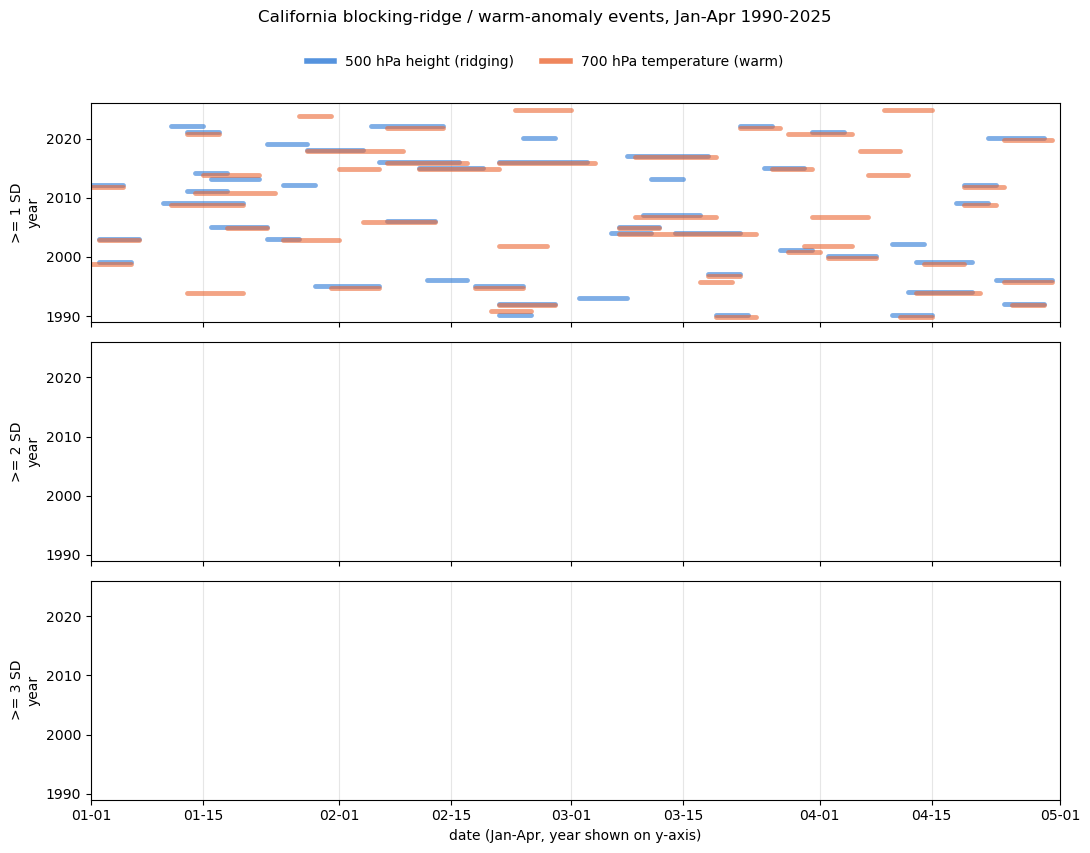

In [11]:
import matplotlib.dates as mdates

COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
Y_OFFSET = {'500 hPa height (ridging)': 0.1, '700 hPa temperature (warm)': -0.18}

fig, axes = plt.subplots(len(THRESHOLDS), 1, figsize=(11, 8), sharex=True)
for ax, thr in zip(axes, THRESHOLDS):
    sub = events_df[events_df.threshold_sd == thr]
    for _, row in sub.iterrows():
        year = row.start_date.year
        x0 = pd.Timestamp(2000, row.start_date.month, row.start_date.day)
        x1 = pd.Timestamp(2000, row.end_date.month, row.end_date.day) if row.end_date.year == row.start_date.year else pd.Timestamp(2000, 4, 30)
        y = year + Y_OFFSET[row.variable]
        ax.plot([x0, x1], [y, y], color=COLOR[row.variable], linewidth=3.5,
                 alpha=0.6, solid_capstyle='round')
    ax.set_ylabel(f'>= {thr} SD\nyear')
    ax.set_ylim(1989, 2026)
    # explicit x-limits instead of matplotlib's default autoscale, which pads a
    # few days into Dec 1999 on the left and cuts awkwardly past Apr 30 on the
    # right; 05-01 gives the last event's line a one-day buffer from the edge.
    ax.set_xlim(pd.Timestamp(2000, 1, 1), pd.Timestamp(2000, 5, 1))
    # ticks as MM-DD, not the full 2000-MM-DD -- the placeholder year 2000 used
    # to lay all events on one calendar axis isn't real data and shouldn't show.
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    ax.grid(axis='x', color='0.9')
axes[-1].set_xlabel('date (Jan-Apr, year shown on y-axis)')
handles = [plt.Line2D([0], [0], color=c, linewidth=4, alpha=0.8) for c in COLOR.values()]
fig.legend(handles, COLOR.keys(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.suptitle('California blocking-ridge / warm-anomaly events, Jan-Apr 1990-2025', y=1.06)
fig.tight_layout()
plt.show()

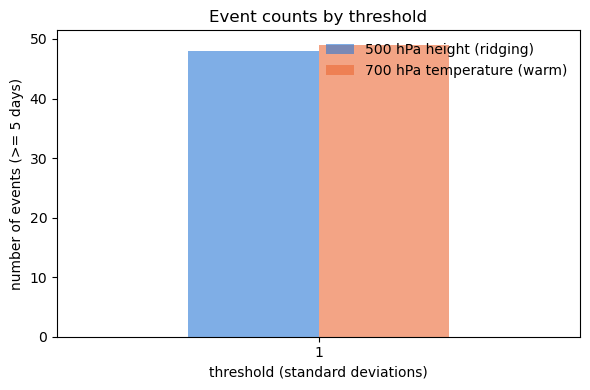

In [14]:
counts = events_df.groupby(['threshold_sd', 'variable']).size().unstack('variable').reindex(columns=COLOR.keys())
ax = counts.plot(kind='bar', color=list(COLOR.values()), figsize=(6, 4), rot=0, alpha=0.6)
ax.set_xlabel('threshold (standard deviations)')
ax.set_ylabel('number of events (>= 5 days)')
ax.set_title('Event counts by threshold')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

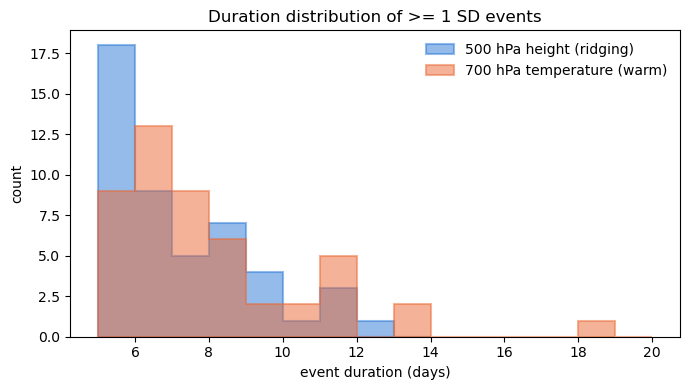

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, label in VARS:
    durations = events_df.loc[(events_df.variable == label) & (events_df.threshold_sd == 1), 'duration_days']
    ax.hist(durations, bins=range(5, int(durations.max()) + 3), alpha=0.5, label=label,
             color=COLOR[label], edgecolor=COLOR[label], linewidth=1.5, histtype='stepfilled')
ax.set_xlabel('event duration (days)')
ax.set_ylabel('count')
ax.set_title('Duration distribution of >= 1 SD events')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Validation

Independent checks on whether the detected events reflect a real synoptic signal:
1. **Climatology sanity** -- standardized anomalies should have ~zero mean and unit std.
2. **Physical consistency** -- Z500 ridging and T700 warmth should be positively correlated.
3. **Event co-occurrence** -- ridging and warm-event days should substantially overlap.
4. **Face validity** -- known, well-documented persistent-ridge winters over the western
   US (e.g. the 2013-2015 "Ridiculously Resilient Ridge", winter 2021-2022) should show
   up as detected ridging events.
5. **Spatial check** -- compositing the full gridded Z500/T700 fields over the detected
   events (one mean field per *event*, not per day, so a 13-day event doesn't get 13x
   the weight of a 3-day event) should show a coherent basin-scale ridge/warm pattern,
   not a pattern confined to (or absent from) the CA box itself. A block bootstrap that
   resamples whole events (the actual independent unit here, not days -- consecutive
   days within one event are highly autocorrelated) gives a 95% CI per grid point;
   hatched regions are not significant at that level.

In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature


def event_days(variable, threshold_sd=1):
    sub = events_df[(events_df.variable == variable) & (events_df.threshold_sd == threshold_sd)]
    days = set()
    for _, row in sub.iterrows():
        days.update(pd.date_range(row.start_date, row.end_date))
    return days


print('Standardized-anomaly sanity check (should be close to mean=0, std=1 if the '
      'calendar-day climatology removed the seasonal cycle correctly):')
df[['z500_sanom', 't700_sanom']].agg(['mean', 'std', 'min', 'max'])

Standardized-anomaly sanity check (should be close to mean=0, std=1 if the calendar-day climatology removed the seasonal cycle correctly):


,z500_sanom,t700_sanom
mean,0.000094,-0.000150
std,0.993207,0.994326
min,-3.882557,-3.523486
max,2.286580,2.374307


Correlation between Z500 and T700 standardized anomalies: r = 0.92


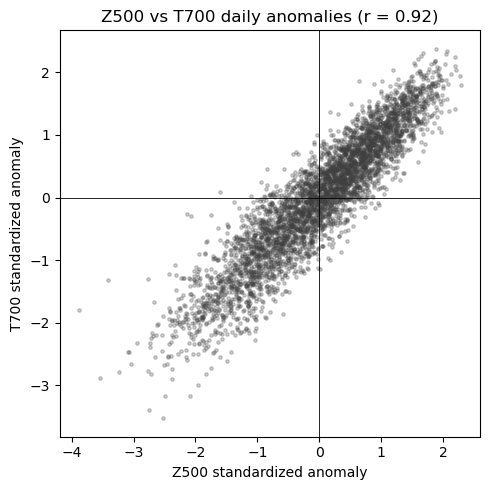

In [15]:
corr = df['z500_sanom'].corr(df['t700_sanom'])
print(f'Correlation between Z500 and T700 standardized anomalies: r = {corr:.2f}')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['z500_sanom'], df['t700_sanom'], s=6, alpha=0.25, color='0.25')
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
ax.set_xlabel('Z500 standardized anomaly')
ax.set_ylabel('T700 standardized anomaly')
ax.set_title(f'Z500 vs T700 daily anomalies (r = {corr:.2f})')
plt.tight_layout()
plt.show()

In [12]:
z_days = event_days('500 hPa height (ridging)', 1)
t_days = event_days('700 hPa temperature (warm)', 1)
overlap = z_days & t_days
print(f'Z500 ridging (>=1 SD) event-days: {len(z_days)}')
print(f'T700 warm (>=1 SD) event-days:    {len(t_days)}')
print(f'Days flagged by both:             {len(overlap)}  '
      f'({100 * len(overlap) / min(len(z_days), len(t_days)):.0f}% of the smaller set)')
print('A high overlap fraction is expected: a 500 hPa ridge drives subsidence that '
      'adiabatically warms the 700 hPa layer beneath it.')

Z500 ridging (>=1 SD) event-days: 326
T700 warm (>=1 SD) event-days:    371
Days flagged by both:             245  (75% of the smaller set)
A high overlap fraction is expected: a 500 hPa ridge drives subsidence that adiabatically warms the 700 hPa layer beneath it.


In [13]:
# Spot-check against documented persistent-ridge winters over the western US/CA.
# Sources (verified by web search, Oct 2026):
# - "Ridiculously Resilient Ridge" (RRR): nickname coined by Daniel Swain (Weather
#   West blog, Dec 2013); formalized in Swain et al. 2015, Geophysical Research
#   Letters 42(22), 9999-10003, doi:10.1002/2015GL066628 ("A tale of two California
#   droughts"). Per that paper, the RRR pattern recurred across winters 2012-13,
#   2013-14, and 2014-15 -- https://en.wikipedia.org/wiki/Ridiculously_Resilient_Ridge
# - Winter 2021-2022: NOAA/CNRFC reported California's driest Jan-Mar in the
#   100-year precipitation record, immediately following the wettest December on
#   record at the UC Berkeley Central Sierra Snow Lab -- CNRFC Water Resources
#   Update, 2022-04-15 (cnrfc.noaa.gov/WaterResourcesUpdates/WRUpdate20220415.pdf)
#   and Washington Post, 2022-03-01.
KNOWN_RIDGE_WINTERS = {
    'winter 2012-2013 (RRR onset)': ('2013-01-01', '2013-04-30'),
    'winter 2013-2014 (RRR, driest CA winter on record)': ('2014-01-01', '2014-04-30'),
    'winter 2014-2015 (RRR persists)': ('2015-01-01', '2015-04-30'),
    'winter 2021-2022 (driest Jan-Mar in 100-yr record, after wettest Dec on record)': ('2022-01-01', '2022-03-31'),
}

z_events = events_df[(events_df.variable == '500 hPa height (ridging)') & (events_df.threshold_sd == 1)]
for name, (lo, hi) in KNOWN_RIDGE_WINTERS.items():
    lo, hi = pd.Timestamp(lo).date(), pd.Timestamp(hi).date()
    hits = z_events[(z_events.start_date <= hi) & (z_events.end_date >= lo)]
    print(f'{name}:')
    if len(hits):
        print(hits[['start_date', 'end_date', 'duration_days', 'peak_sanom']].to_string(index=False))
    else:
        print('  NO ridging event detected in this window -- worth a closer look.')
    print()

winter 2012-2013 (RRR onset):
start_date   end_date  duration_days  peak_sanom
2013-01-16 2013-01-22            7.0    1.476496
2013-03-11 2013-03-15            5.0    1.687232

winter 2013-2014 (RRR, driest CA winter on record):
start_date   end_date  duration_days  peak_sanom
2014-01-14 2014-01-18            5.0    1.636727

winter 2014-2015 (RRR persists):
start_date   end_date  duration_days  peak_sanom
2015-02-11 2015-02-19            9.0    1.892387
2015-03-25 2015-03-30            6.0    1.935295

winter 2021-2022 (driest Jan-Mar in 100-yr record, after wettest Dec on record):
start_date   end_date  duration_days  peak_sanom
2022-01-11 2022-01-15            5.0    1.612349
2022-02-05 2022-02-14           10.0    1.557238
2022-03-22 2022-03-26            5.0    1.895923



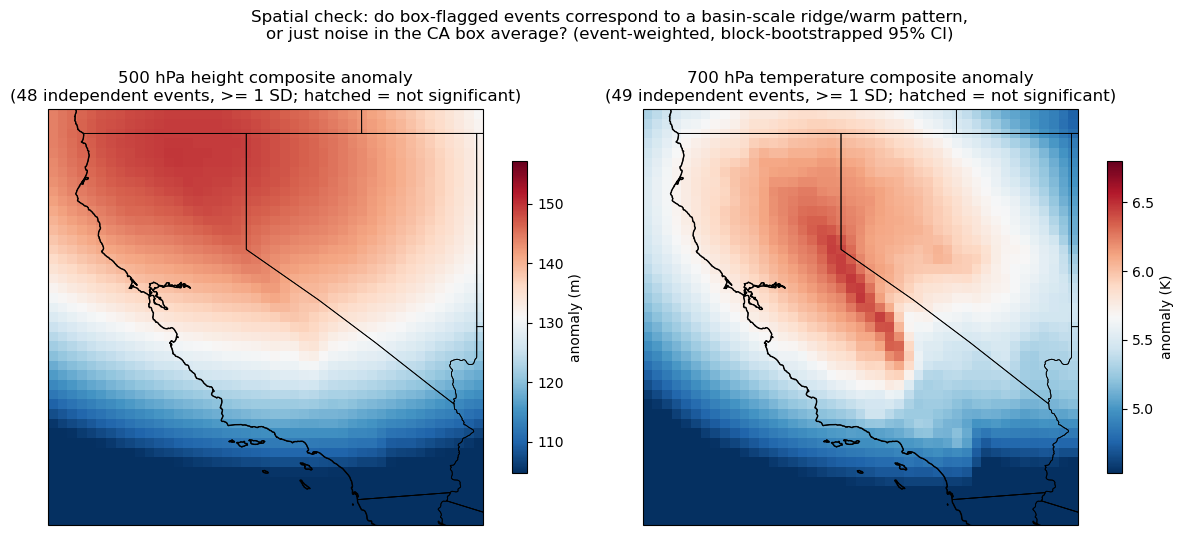

In [14]:
def gridpoint_climatology(da, window=CLIM_WINDOW):
    """Per-calendar-day grid-point mean, pooling +/-window days across all years
    (same leap-year-safe (month, day) keying as the box-average climatology)
    so we can check the *spatial* pattern behind each box-flagged event."""
    time_index = pd.to_datetime(da.time.values)
    md_key = list(zip(time_index.month, time_index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])

    vals = da.load().values  # (time, lat, lon)
    clim = np.empty((len(unique_keys),) + vals.shape[1:])
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        clim[idx] = vals[mask].mean(axis=0)
    return vals - clim[season_idx]


def event_mean_fields(events_sub, grid_anom, time_index):
    """One mean anomaly field per event (not per day), averaged over that
    event's own day span -- equal weight per event regardless of duration."""
    fields = []
    for _, row in events_sub.iterrows():
        mask = (time_index.date >= row.start_date) & (time_index.date <= row.end_date)
        fields.append(grid_anom[mask].mean(axis=0))
    return np.stack(fields)


def bootstrap_composite_ci(event_fields, n_boot=1000, seed=42):
    """Block bootstrap over *events* (the actual independent sampling unit --
    days within one event are highly autocorrelated, so resampling days instead
    of events would badly understate the true uncertainty). Returns the 95% CI
    bounds per grid point."""
    rng = np.random.default_rng(seed)
    n_events = event_fields.shape[0]
    boot = np.empty((n_boot,) + event_fields.shape[1:])
    for b in range(n_boot):
        idx = rng.integers(0, n_events, size=n_events)
        boot[b] = event_fields[idx].mean(axis=0)
    return np.percentile(boot, [2.5, 97.5], axis=0)


z500_grid_anom = gridpoint_climatology(ds['z500'])
t700_grid_anom = gridpoint_climatology(ds['t700'])
time_index = pd.to_datetime(ds.time.values)
lon_plot = np.where(ds.longitude.values > 180, ds.longitude.values - 360, ds.longitude.values)

z_events_1sd = events_df[(events_df.variable == '500 hPa height (ridging)') & (events_df.threshold_sd == 1)]
t_events_1sd = events_df[(events_df.variable == '700 hPa temperature (warm)') & (events_df.threshold_sd == 1)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree()})
for ax, grid_anom, events_sub, var_label, units in zip(
    axes,
    [z500_grid_anom, t700_grid_anom],
    [z_events_1sd, t_events_1sd],
    ['500 hPa height', '700 hPa temperature'],
    ['m', 'K'],
):
    event_fields = event_mean_fields(events_sub, grid_anom, time_index)
    composite = event_fields.mean(axis=0)  # equal weight per event
    ci_lo, ci_hi = bootstrap_composite_ci(event_fields)
    not_significant = (ci_lo <= 0) & (ci_hi >= 0)  # zero inside the 95% CI

    # scale the color limits to the actual composite magnitude -- a fixed vmax
    # across variables with very different anomaly scales (tens of m vs a few K)
    # saturates the whole map to one color and hides the spatial structure.
    vmax = np.abs(composite).max() * 1.05
    pcm = ax.pcolormesh(lon_plot, ds.latitude.values, composite, cmap='RdBu_r',
                         vmin=vmax * 2 / 3., vmax=vmax, shading='auto', transform=ccrs.PlateCarree())
    ax.contourf(lon_plot, ds.latitude.values, not_significant.astype(int),
                levels=[0.5, 1.5], colors='none', hatches=['...'],
                transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.STATES, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.6)
    ax.set_title(f'{var_label} composite anomaly\n'
                 f'({len(events_sub)} independent events, >= 1 SD; hatched = not significant)')
    fig.colorbar(pcm, ax=ax, shrink=0.75, label=f'anomaly ({units})')
fig.suptitle(
    'Spatial check: do box-flagged events correspond to a basin-scale ridge/warm pattern,\n'
    'or just noise in the CA box average? (event-weighted, block-bootstrapped 95% CI)',
    y=1.06,
)
plt.tight_layout()
plt.show()

**Note (from an earlier, pre-detrending run at this same MIN_DURATION=5; kept for
reference -- verified to match a pre-detrend recompute of the current pipeline, see
the live comparison a few cells below):**

I re-derived the anomaly series to confirm. For Jan-Apr 1990-2025:

| | max sigma ever reached | days >=2sigma | longest run >=2sigma | days >=3sigma |
|---|---|---|---|---|
| Z500 | 2.26 | 24 of 4329 | 2 days | 0 |
| T700 | 2.41 | 27 of 4329 | 3 days | 0 |

- 3-sigma never happens at all -- the standardized anomaly literally never reaches 3 sigma
  for either variable in this 36-year CA-box-averaged record, so that threshold is empty
  by construction, not a detection failure.
- 2-sigma happens, but never persists -- it occurs on ~25 days total, but the longest
  unbroken run is 2-3 days, well short of a 5-day minimum. A single day spiking to 2 sigma
  and then relaxing the next day is common; staying pinned there for 5 straight days
  essentially never happened in this record.
- 1-sigma is where persistence shows up -- runs there reach up to 12 days (Z500) and
  18 days (T700).

Two things compound to make 2-3 sigma + persistence this rare: box-averaging over the
whole CA domain smooths out local extremes, and the calendar-day climatology (narrow
+/-5-day window) already resolves a lot of the "expected" synoptic variance into the
mean, so what's left as anomaly is tighter than a coarser monthly climatology would give.

Levers to get more 2sigma/3sigma events: shrink `MIN_DURATION`, or shrink the spatial
average (sub-box or single grid point) so extremes aren't averaged away.

In [15]:
# Pre-detrend vs detrended comparison, computed here for THIS notebook's own
# parameters (MIN_DURATION=5). An earlier version of the next markdown cell
# quoted pre/post event counts (107/115, 110, etc.) that actually came from
# the MIN_DURATION=3 sibling notebook (CA_z500_t700_blocking_events_detrend_3day.ipynb),
# not this one -- recomputing live here avoids that mismatch happening again.
df_pre = df.copy()
for col in ['z500', 't700']:
    m, s = climatology(df, col)
    df_pre[f'{col}_sanom'] = (df[col] - m) / s

pre_events = []
for col, label in VARS:
    sanom = df_pre[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        pre_events.append(ev)
pre_events_df = pd.concat(pre_events, ignore_index=True)

compare_counts = pd.DataFrame({
    'pre-detrend': pre_events_df[pre_events_df.threshold_sd == 1].groupby('variable').size(),
    'detrended (current)': events_df[events_df.threshold_sd == 1].groupby('variable').size(),
})
print(f'>= 1 SD event counts, pre-detrend vs detrended (MIN_DURATION = {MIN_DURATION}):')
print(compare_counts)

r_pre = df_pre['z500_sanom'].corr(df_pre['t700_sanom'])
r_dt = df['z500_sanom'].corr(df['t700_sanom'])
print(f'\nZ500/T700 correlation: pre-detrend r={r_pre:.2f}, detrended r={r_dt:.2f}')


def decade_counts(edf, variable, threshold_sd=1):
    sub = edf[(edf.variable == variable) & (edf.threshold_sd == threshold_sd)]
    years = sub.start_date.apply(lambda d: d.year)
    decades = pd.cut(years, bins=[1989, 1999, 2009, 2019, 2026],
                      labels=['1990s', '2000s', '2010s', '2020s'])
    return decades.value_counts().sort_index()


print('\nZ500 >=1 SD events by decade:')
decade_compare = pd.DataFrame({
    'pre-detrend': decade_counts(pre_events_df, '500 hPa height (ridging)'),
    'detrended': decade_counts(events_df, '500 hPa height (ridging)'),
})
decade_compare

>= 1 SD event counts, pre-detrend vs detrended (MIN_DURATION = 5):
                            pre-detrend  detrended (current)
variable                                                    
500 hPa height (ridging)             47                   48
700 hPa temperature (warm)           49                   49

Z500/T700 correlation: pre-detrend r=0.92, detrended r=0.92

Z500 >=1 SD events by decade:


,pre-detrend,detrended
start_date,,
1990s,12,14
2000s,10,13
2010s,16,14
2020s,9,7


#### detrend vs pre-detrend, for this notebook's own MIN_DURATION=5 pipeline

Conclusion (from the live comparison computed above, not copied from another
notebook): at MIN_DURATION=5, detrending barely moves the *overall* event
count -- Z500 ridging >=1 sigma goes from 47 (pre-detrend) to 48 (detrended),
T700 warm >=1 sigma stays at 49 -- and the Z500/T700 correlation is unchanged
(r=0.92). What detrending *does* change is the decade-by-decade distribution:
Z500 >=1 sigma events shift from {1990s: 12, 2000s: 10, 2010s: 16, 2020s: 9}
pre-detrend to {1990s: 14, 2000s: 13, 2010s: 14, 2020s: 7} detrended -- more
events recovered in the early record, fewer in the 2020s, consistent with
correcting the warm/high bias a fixed 36-year baseline bakes into recent
years and the cool/low bias it bakes into the 1990s. So: for this notebook's actual parameters, detrending's effect on the *total* count is negligible, but it meaningfully reshapes the apparent trend across decades 

#### Sensitivity: MIN_DURATION=3 vs MIN_DURATION=5
CA_z500_t700_blocking_events_mindur_comparison.ipynb

## 6. Sierra Nevada sub-box comparison

The full CA box (32-42.5N, 125-114W) spans coast, Central Valley, and desert -- only a
fraction of it is the Sierra Nevada, where snowpack actually accumulates. For
drought/snowpack research the question that matters is whether the full-box average is
diluting or distorting the ridging-driven signal relevant to the Sierra, or whether it
tracks it well enough to use as-is. This repeats the same box-average + detrended
climatology + gap-tolerant event-detection pipeline over a tighter Sierra-focused
sub-box (36-40N, 121-118.5W -- the western-slope snow zone, which already falls inside
the extracted CA-box data, so no new extraction is needed) and compares the two.

In [16]:
SIERRA_LAT_S, SIERRA_LAT_N = 36.0, 40.0
SIERRA_LON_W, SIERRA_LON_E = 239.0, 241.5  # -121.0 to -118.5 deg E -- western-slope snow zone

sierra_weights = np.cos(np.deg2rad(ds.latitude.sel(latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S))))
z500_sierra = ds.z500.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(SIERRA_LON_W, SIERRA_LON_E),
).weighted(sierra_weights).mean(dim=('latitude', 'longitude')).compute()
t700_sierra = ds.t700.sel(
    latitude=slice(SIERRA_LAT_N, SIERRA_LAT_S), longitude=slice(SIERRA_LON_W, SIERRA_LON_E),
).weighted(sierra_weights).mean(dim=('latitude', 'longitude')).compute()

df_sierra = pd.DataFrame(
    {'z500': z500_sierra.values, 't700': t700_sierra.values},
    index=pd.to_datetime(ds.time.values),
).sort_index()
df_sierra = df_sierra[df_sierra.index.month.isin([1, 2, 3, 4])]

for col in ['z500', 't700']:
    m, s = climatology(df_sierra, col)
    trend = fit_year_trend(df_sierra, col, m, label='Sierra ')
    df_sierra[f'{col}_clim_mean'] = m + trend
    df_sierra[f'{col}_clim_std'] = s
    df_sierra[f'{col}_sanom'] = (df_sierra[col] - df_sierra[f'{col}_clim_mean']) / df_sierra[f'{col}_clim_std']

print(f'\nSierra sub-box: {SIERRA_LAT_S}-{SIERRA_LAT_N}N, '
      f'{360 - SIERRA_LON_E}-{360 - SIERRA_LON_W}W')
df_sierra[['z500_sanom', 't700_sanom']].describe()

Sierra z500: year-trend = +7.169 per decade (p = 0.075, r = 0.30) -- removing this from the climatological baseline before standardizing
Sierra t700: year-trend = +0.181 per decade (p = 0.282, r = 0.18) -- removing this from the climatological baseline before standardizing

Sierra sub-box: 36.0-40.0N, 118.5-121.0W


,z500_sanom,t700_sanom
count,4329.000000,4329.000000
mean,0.000055,-0.000271
std,0.994572,0.995939
min,-3.598342,-3.651735
25%,-0.702435,-0.701923
50%,0.114896,0.089806
75%,0.760483,0.759707
max,2.174271,2.397692


In [17]:
dates_sierra = df_sierra.index
sierra_all_events = []
for col, label in VARS:
    sanom = df_sierra[f'{col}_sanom'].values
    for thr in THRESHOLDS:
        ev = find_events(dates_sierra, sanom, threshold=thr)
        ev.insert(0, 'threshold_sd', thr)
        ev.insert(0, 'variable', label)
        sierra_all_events.append(ev)

sierra_events_df = pd.concat(sierra_all_events, ignore_index=True)
sierra_events_df = sierra_events_df.sort_values(['variable', 'threshold_sd', 'start_date']).reset_index(drop=True)
print(f'Sierra sub-box: {len(sierra_events_df)} events found (same MIN_DURATION/MAX_GAP/THRESHOLDS as the CA box)')
sierra_events_df.groupby(['variable', 'threshold_sd']).agg(
    n_events=('duration_days', 'size'),
    mean_duration=('duration_days', 'mean'),
    max_duration=('duration_days', 'max'),
)

Sierra sub-box: 101 events found (same MIN_DURATION/MAX_GAP/THRESHOLDS as the CA box)


,,n_events,mean_duration,max_duration
variable,threshold_sd,,,
500 hPa height (ridging),1,46,6.739130,11.0
700 hPa temperature (warm),1,55,7.218182,18.0


Event count comparison, CA box vs Sierra sub-box (>= 1 SD):
                            CA box  Sierra sub-box
variable                                          
500 hPa height (ridging)        48              46
700 hPa temperature (warm)      49              55

z500: CA-box vs Sierra-sub-box standardized-anomaly correlation r = 0.99
t700: CA-box vs Sierra-sub-box standardized-anomaly correlation r = 0.98

CA-box ridging event-days: 326, Sierra ridging event-days: 310, overlap: 292 (94% of the smaller set)
A high correlation/overlap would mean the full CA-box average is a fine proxy for the Sierra; a low one would mean box-averaging is diluting or distorting the signal that actually matters for snowpack.


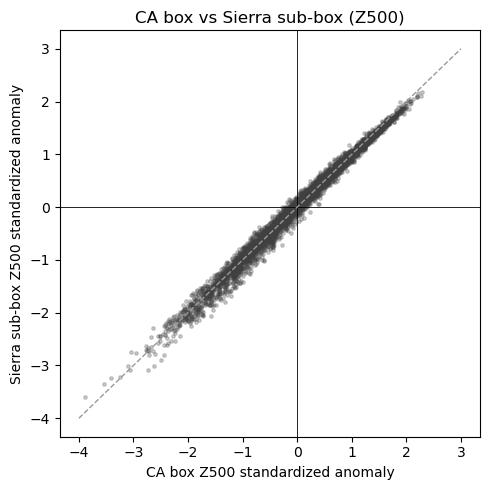

In [18]:
print('Event count comparison, CA box vs Sierra sub-box (>= 1 SD):')
compare = pd.DataFrame({
    'CA box': events_df[events_df.threshold_sd == 1].groupby('variable').size(),
    'Sierra sub-box': sierra_events_df[sierra_events_df.threshold_sd == 1].groupby('variable').size(),
})
print(compare)
print()

for col in ['z500', 't700']:
    r = df[f'{col}_sanom'].corr(df_sierra[f'{col}_sanom'])
    print(f'{col}: CA-box vs Sierra-sub-box standardized-anomaly correlation r = {r:.2f}')


def event_days_from(edf, variable, threshold_sd=1):
    sub = edf[(edf.variable == variable) & (edf.threshold_sd == threshold_sd)]
    days = set()
    for _, row in sub.iterrows():
        days.update(pd.date_range(row.start_date, row.end_date))
    return days


ca_ridge_days = event_days('500 hPa height (ridging)', 1)
sierra_ridge_days = event_days_from(sierra_events_df, '500 hPa height (ridging)', 1)
overlap = ca_ridge_days & sierra_ridge_days
print(f'\nCA-box ridging event-days: {len(ca_ridge_days)}, Sierra ridging event-days: {len(sierra_ridge_days)}, '
      f'overlap: {len(overlap)} ({100 * len(overlap) / min(len(ca_ridge_days), len(sierra_ridge_days)):.0f}% of the smaller set)')
print('A high correlation/overlap would mean the full CA-box average is a fine proxy for '
      'the Sierra; a low one would mean box-averaging is diluting or distorting the '
      'signal that actually matters for snowpack.')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(df['z500_sanom'], df_sierra['z500_sanom'], s=6, alpha=0.25, color='0.25')
ax.axhline(0, color='k', lw=0.6)
ax.axvline(0, color='k', lw=0.6)
ax.plot([-4, 3], [-4, 3], color='0.6', lw=1, ls='--')  # 1:1 reference line
ax.set_xlabel('CA box Z500 standardized anomaly')
ax.set_ylabel('Sierra sub-box Z500 standardized anomaly')
ax.set_title('CA box vs Sierra sub-box (Z500)')
plt.tight_layout()
plt.show()

## 7. Precipitation and snowfall validation
Using `precip_sf_ca_<year>.nc` (produced by `get_precip_sf_ca.py` /
`job_array_get_precip_sf_ca.pbs`) -- daily total precipitation (TP = large-scale +
convective) and snowfall water-equivalent (SF) over the same CA box, for the same
Jan-Apr 1990-2025 period, derived from ERA5's accumulated surface-forecast fields.

**This section is only for *relative* comparisons (percent of normal, dry vs. wet) :** The accumulation-stitching logic (in get_precip_sf_ca.py reconstructing a daily precipitation/snowfall total from ERA5's raw forecast output) was validated
against this notebook's own first detected Z500 ridging event (1990-02-21 to 1990-02-25, MIN_DURATION=5) -- box-mean precip stayed within 0.0001-0.009 mm throughout -- and against ERA5's own file-level maxima. A cross-check against the well-documented January 1997 California AR flood showed this 0.25-degree resolution of ERA5 substantially understates the most extreme, localized orographic station totals -- a known ERA5 resolution limitation in steep terrain. 

In [19]:
precip_files = [DATA_DIR / f'precip_sf_ca_{y}.nc' for y in YEARS]
missing = [f.name for f in precip_files if not f.exists()]
if missing:
    raise FileNotFoundError(
        f'{len(missing)} year file(s) missing from {DATA_DIR}: {missing[:5]}...\n'
        'Run job_array_get_precip_sf_ca.pbs first (see get_precip_sf_ca.py).'
    )

ds_precip = xr.open_mfdataset(precip_files, combine='by_coords')
precip_weights = np.cos(np.deg2rad(ds_precip.latitude))
tp_box = ds_precip.tp.weighted(precip_weights).mean(dim=('latitude', 'longitude')).compute()
sf_box = ds_precip.sf.weighted(precip_weights).mean(dim=('latitude', 'longitude')).compute()

df_precip = pd.DataFrame(
    {'tp': tp_box.values, 'sf': sf_box.values},
    index=pd.to_datetime(ds_precip.time.values),
).sort_index()
df_precip = df_precip[df_precip.index.month.isin([1, 2, 3, 4])]


def precip_climatology_mean(df, col, window=CLIM_WINDOW):
    """Calendar-day climatological mean only -- no std, and deliberately no
    detrending. Precip/snowfall are zero-inflated and strongly right-skewed,
    so a parametric sigma threshold doesn't apply the way it does for Z500/T700;
    we only need a 'normal for this day' baseline to express actual precip as a
    ratio/percent of normal."""
    md_key = list(zip(df.index.month, df.index.day))
    unique_keys = sorted(set(md_key))
    key_to_idx = {k: i for i, k in enumerate(unique_keys)}
    season_idx = np.array([key_to_idx[k] for k in md_key])
    clim_mean = {}
    for k, idx in key_to_idx.items():
        mask = (season_idx >= idx - window) & (season_idx <= idx + window)
        clim_mean[k] = df[col].values[mask].mean()
    return np.array([clim_mean[k] for k in md_key])


for col in ['tp', 'sf']:
    df_precip[f'{col}_clim_mean'] = precip_climatology_mean(df_precip, col)

print(df_precip.shape, '(should match df.shape -- same Jan-Apr 1990-2025 daily record)')
df_precip[['tp', 'tp_clim_mean', 'sf', 'sf_clim_mean']].describe()

(4329, 4) (should match df.shape -- same Jan-Apr 1990-2025 daily record)


,tp,tp_clim_mean,sf,sf_clim_mean
count,4329.000000,4329.000000,4329.000000,4329.000000
mean,0.150355,0.150484,0.037171,0.037203
std,0.242660,0.041875,0.067872,0.012179
min,0.000000,0.062917,0.000000,0.011432
25%,0.004511,0.109529,0.000085,0.028928
50%,0.043587,0.162304,0.005116,0.039236
75%,0.196217,0.182019,0.043520,0.047413
max,2.200018,0.206863,0.819384,0.055335


In [20]:
from scipy.stats import wilcoxon


def event_mean_ratio(events_sub, df_precip, col):
    """Per-event mean (actual / climatological-normal) -- one value per
    independent *event*, not per day, so the statistical test below doesn't
    repeat the day-level pseudo-replication problem from the composite-map
    section (consecutive days within an event are highly autocorrelated)."""
    vals = []
    for _, row in events_sub.iterrows():
        mask = (df_precip.index.date >= row.start_date) & (df_precip.index.date <= row.end_date)
        actual = df_precip.loc[mask, col].mean()
        normal = df_precip.loc[mask, f'{col}_clim_mean'].mean()
        vals.append(actual / normal if normal > 0 else np.nan)
    return np.array(vals)


print('Is precipitation/snowfall actually suppressed during detected ridging/warm events?')
print('(one-sample Wilcoxon signed-rank test per variable, n = independent events, vs. ratio=1 null)\n')
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)]
        ratios = event_mean_ratio(sub_events, df_precip, col)
        ratios = ratios[~np.isnan(ratios)]
        stat, p = wilcoxon(ratios - 1, alternative='less')
        print(f'{units} during {label} events: median = {np.median(ratios) * 100:.0f}% of normal '
              f'(n={len(ratios)} events, one-sided p={p:.2e})')
    print()

Is precipitation/snowfall actually suppressed during detected ridging/warm events?
(one-sample Wilcoxon signed-rank test per variable, n = independent events, vs. ratio=1 null)

precip during 500 hPa height (ridging) events: median = 3% of normal (n=48 events, one-sided p=3.55e-15)
precip during 700 hPa temperature (warm) events: median = 6% of normal (n=49 events, one-sided p=5.77e-09)

snowfall during 500 hPa height (ridging) events: median = 0% of normal (n=48 events, one-sided p=8.14e-10)
snowfall during 700 hPa temperature (warm) events: median = 0% of normal (n=49 events, one-sided p=5.88e-10)



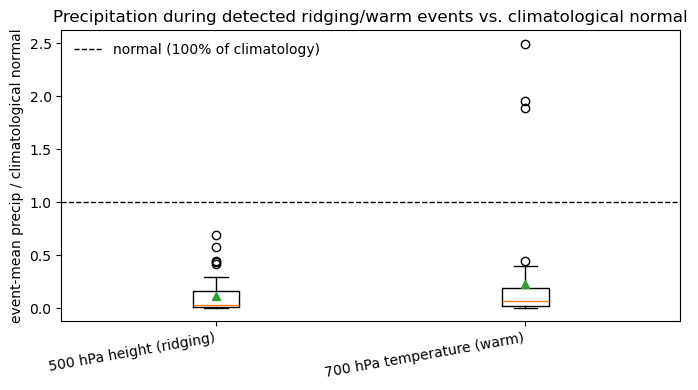

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
box_data, box_labels = [], []
for col, label in VARS:
    sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)]
    ratios = event_mean_ratio(sub_events, df_precip, 'tp')
    box_data.append(ratios[~np.isnan(ratios)])
    box_labels.append(label)
ax.boxplot(box_data, tick_labels=box_labels, showmeans=True)
ax.axhline(1.0, color='k', ls='--', lw=1, label='normal (100% of climatology)')
ax.set_ylabel('event-mean precip / climatological normal')
ax.set_title('Precipitation during detected ridging/warm events vs. climatological normal')
ax.legend(frameon=False)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

In [22]:
from scipy.stats import kruskal


def event_decade(events_sub):
    years = events_sub.start_date.apply(lambda d: d.year)
    return pd.cut(years, bins=[1989, 1999, 2009, 2019, 2026], labels=['1990s', '2000s', '2010s', '2020s'])


print('Precip/snowfall ratio-to-normal during ridging/warm events, by decade')
print('(small per-decade n -- indicative, not strongly powered; see Kruskal-Wallis below)\n')

rows = []
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        for decade, grp in sub_events.groupby('decade', observed=True):
            vals = grp['ratio'].dropna()
            rows.append({
                'metric': units, 'variable': label, 'decade': decade,
                'n_events': len(vals),
                'median_pct_of_normal': round(vals.median() * 100) if len(vals) else np.nan,
            })

decade_table = pd.DataFrame(rows)
decade_pivot = decade_table.pivot_table(
    index=['metric', 'variable'], columns='decade', values='median_pct_of_normal', observed=True,
)
print(decade_pivot.to_string())

print('\nKruskal-Wallis test for a difference in ratio distribution across decades:')
for col, units in [('tp', 'precip'), ('sf', 'snowfall')]:
    for var_col, label in VARS:
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        groups = [g['ratio'].dropna().values for _, g in sub_events.groupby('decade', observed=True)]
        groups = [g for g in groups if len(g) >= 3]
        if len(groups) >= 2:
            stat, p = kruskal(*groups)
            print(f'  {units} during {label} events: p = {p:.3f}')

Precip/snowfall ratio-to-normal during ridging/warm events, by decade
(small per-decade n -- indicative, not strongly powered; see Kruskal-Wallis below)

decade                               1990s  2000s  2010s  2020s
metric   variable                                              
precip   500 hPa height (ridging)     13.0    2.0    2.0    2.0
         700 hPa temperature (warm)    5.0    8.0   11.0    7.0
snowfall 500 hPa height (ridging)      0.0    0.0    0.0    0.0
         700 hPa temperature (warm)    0.0    1.0    2.0    1.0

Kruskal-Wallis test for a difference in ratio distribution across decades:
  precip during 500 hPa height (ridging) events: p = 0.173
  precip during 700 hPa temperature (warm) events: p = 0.763
  snowfall during 500 hPa height (ridging) events: p = 0.848
  snowfall during 700 hPa temperature (warm) events: p = 0.014


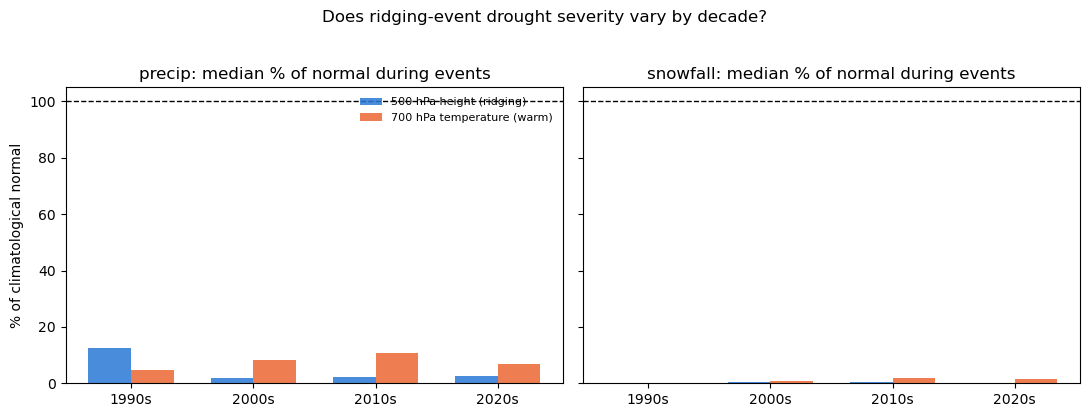

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
decades = ['1990s', '2000s', '2010s', '2020s']
x = np.arange(len(decades))
width = 0.35

for ax, (col, units) in zip(axes, [('tp', 'precip'), ('sf', 'snowfall')]):
    for i, (var_col, label) in enumerate(VARS):
        sub_events = events_df[(events_df.variable == label) & (events_df.threshold_sd == 1)].copy()
        sub_events['ratio'] = event_mean_ratio(sub_events, df_precip, col)
        sub_events['decade'] = event_decade(sub_events)
        medians = sub_events.groupby('decade', observed=True)['ratio'].median().reindex(decades) * 100
        ax.bar(x + (i - 0.5) * width, medians.values, width, label=label, color=COLOR[label], alpha=0.85)
    ax.axhline(100, color='k', ls='--', lw=1)
    ax.set_xticks(x)
    ax.set_xticklabels(decades)
    ax.set_title(f'{units}: median % of normal during events')
axes[0].set_ylabel('% of climatological normal')
axes[0].legend(frameon=False, fontsize=8, loc='upper right')
fig.suptitle('Does ridging-event drought severity vary by decade?', y=1.03)
plt.tight_layout()
plt.show()